# CDC 2023+2024 · подготовка когорты HDP-proxy

Общая когорта включает **все** живорождения резиденток США после одноплодной беременности за 2023–2024 годы с известными `RF_GHYPE` и `RF_EHYPE`, **при записанном отсутствии хронической АГ** (`RF_PHYPE=0`). Каждой записи назначается один из пяти стабильных фолдов; оба года представлены в каждом фолде. Женщины с хронической АГ исключены из основной оценки, поскольку совместная кодировка с `RF_GHYPE` систематически нарушает интерпретацию отрицательных меток. Их количество показано в аудите.

Основная метка: `RF_GHYPE=Y OR RF_EHYPE=Y`. `RF_GHYPE` объединяет гестационную гипертензию и преэклампсию; **отдельный диагноз ПЭ недоступен**. Вторичные метки: HDP-proxy **и** роды до 37 / 34 недель. `OEGEST_COMB` используется только для меток и аудита, никогда как предиктор. Неизвестный срок делает вторичную метку пропущенной. Это сочетание событий не подтверждает преждевременную ПЭ.

Возраст матери записан при родах, поэтому используется лишь как приближение возраста до беременности. Исходы доступны только для живорождений; идентификатора матери и времени начала болезни нет. [NCHS User Guide](https://ftp.cdc.gov/pub/health_statistics/nchs/dataset_documentation/DVS/natality/UserGuide2024.pdf).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/data/preeclampsia_cdc.py").exists())
sys.path.insert(0, str(ROOT))
from src.progress import tqdm
plt.rcParams.update({"figure.figsize": (8, 4.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .2})
BLUE, ORANGE, GREY = "#255B8B", "#D17A31", "#666D78"
MODEL_PALETTE = [("logistic_spline", BLUE), ("hist_gb", ORANGE),
                 ("catboost", "#287D69"), ("lightgbm", "#8062A5")]
RACE6 = {1:"White",2:"Black",3:"AIAN",4:"Asian",5:"NHOPI",6:"Multiple"}  # NCHS MRACE6; social reporting categories
from src.data.preeclampsia_cdc import OUT, FEATURES, OUTCOMES, MISSING_MASKS, QUALITY_MASKS, prepare_all, audit_race_imputation

/Users/nick/Desktop/projects/femfedora/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Сверка источников и сборка общего файла

In [2]:
audit = prepare_all()
checks = pd.DataFrame(audit["year_checks"]).T
display(checks.drop(columns="outcomes"))
print("Parquet:", OUT / "eligible_all_2023_2024.parquet")

CDC 2023: prepare: 100%|██████████| 3.37M/3.37M [00:13<00:00, 255krows/s]
CDC 2024: prepare: 100%|██████████| 3.39M/3.39M [00:13<00:00, 259krows/s]


,raw_rows,resident_rows,foreign_excluded,ghype_yes_official_match,unknown_target,singleton_before_chronic_exclusion,events_before_chronic_exclusion,excluded_chronic_rows,excluded_chronic_recorded_events,eligible_singleton_rows,eligible_singleton_events,eligible_singleton_prevalence,chronic_and_gestational_hypertension_cooccurrence,eclampsia_without_ghype
2023,3605081,3596017,9064,361780,5752,3477379,349530,107665,574,3369714,348956,0.103557,0,6682
2024,3638436,3628934,9502,377267,7301,3510045,364608,115909,646,3394136,363962,0.107233,0,6357


Parquet: /Users/nick/Desktop/projects/femfedora/data/processed/preeclampsia_cdc/eligible_all_2023_2024.parquet


## 2. Исключения, частоты и вторичные метки

In [3]:
cols = ["singleton_before_chronic_exclusion", "excluded_chronic_rows", "excluded_chronic_recorded_events", "eligible_singleton_rows", "eligible_singleton_events", "eligible_singleton_prevalence"]
display(checks[cols])
outcome_table = pd.DataFrame([{"year":year,"outcome":name,**value} for year, row in audit["year_checks"].items() for name,value in row["outcomes"].items()])
display(outcome_table)
assert checks.excluded_chronic_rows.sum() > 0
assert (checks.eligible_singleton_rows + checks.excluded_chronic_rows == checks.singleton_before_chronic_exclusion).all()

,singleton_before_chronic_exclusion,excluded_chronic_rows,excluded_chronic_recorded_events,eligible_singleton_rows,eligible_singleton_events,eligible_singleton_prevalence
2023,3477379,107665,574,3369714,348956,0.103557
2024,3510045,115909,646,3394136,363962,0.107233


,year,outcome,known,events
0,2023,target_hdp_proxy,3369714,348956
1,2023,target_hdp_preterm37,3367943,63342
2,2023,target_hdp_preterm34,3367943,16052
3,2024,target_hdp_proxy,3394136,363962
4,2024,target_hdp_preterm37,3392311,65515
5,2024,target_hdp_preterm34,3392311,16316


## 3. Фолды всех записей и пропуски

,year,fold,rows,events,prevalence
0,2023,0,674090,69767,0.103498
1,2023,1,674392,70049,0.103870
2,2023,2,674305,69964,0.103757
3,2023,3,673529,69698,0.103482
4,2023,4,673398,69478,0.103175
5,2024,0,679183,72890,0.107320
6,2024,1,679613,72921,0.107298
7,2024,2,678345,72616,0.107049
8,2024,3,678094,72722,0.107245
9,2024,4,678901,72813,0.107251


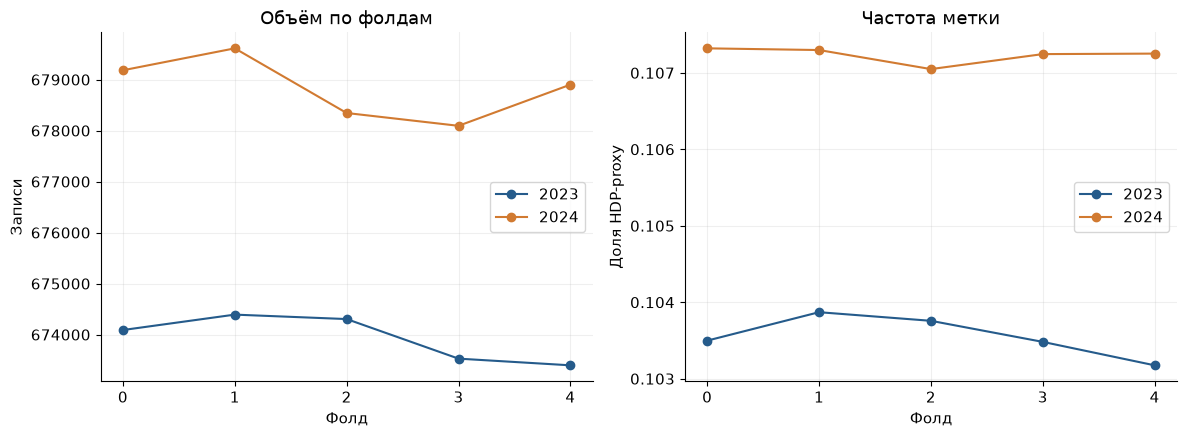

In [4]:
folds = pd.read_csv(OUT / "folds_all.csv")
display(folds)
assert folds.rows.sum() == checks.eligible_singleton_rows.sum()
assert folds.groupby("year").fold.nunique().eq(5).all()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for year, color in [(2023, BLUE), (2024, ORANGE)]:
    part = folds.loc[folds.year.eq(year)]
    axes[0].plot(part.fold, part.rows, marker="o", label=str(year), color=color)
    axes[1].plot(part.fold, part.prevalence, marker="o", label=str(year), color=color)
axes[0].set(xlabel="Фолд", ylabel="Записи", title="Объём по фолдам")
axes[1].set(xlabel="Фолд", ylabel="Доля HDP-proxy", title="Частота метки")
for ax in axes: ax.legend(); ax.set_xticks(range(5))
plt.tight_layout(); plt.show()

year,2023,2024
field,,
age_35_plus,0.0000,0.0000
art_source_reported,0.0000,0.0000
art_status_unknown_reported,0.0000,0.0000
bmi,0.0225,0.0235
bmi_30_plus,0.0225,0.0235
bmi_35_plus,0.0225,0.0235
bmi_missing,0.0000,0.0000
bmi_r,0.0225,0.0235
cig_0,0.0038,0.0044


ART: доля пропусков в процентах, а не во всём наборе


year,2023,2024
field,,
rf_inftr,0.000,6.826
rf_artec,0.056,6.880


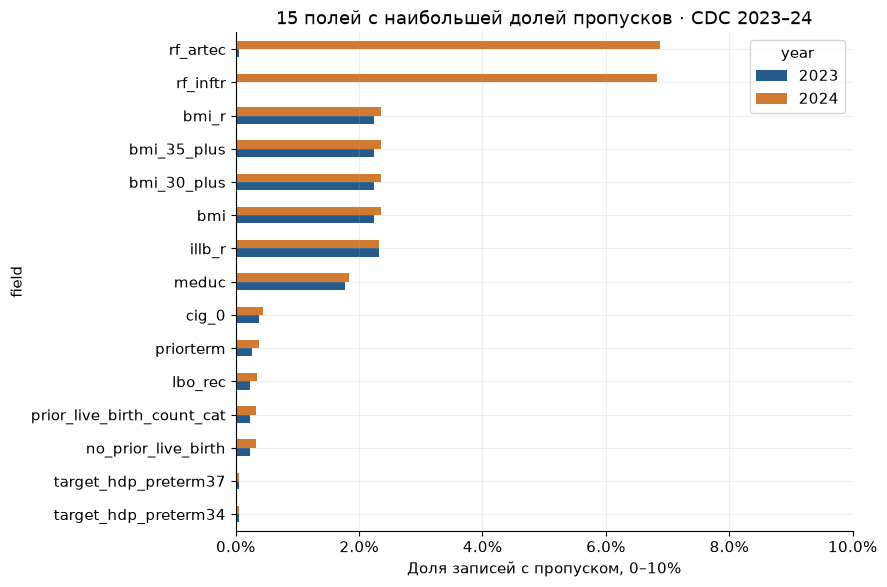

In [5]:
from matplotlib.ticker import PercentFormatter
missing = pd.read_csv(OUT / "missingness_by_year.csv")
table = missing.pivot(index="field", columns="year", values="missing_fraction")
display(table.round(4))
print("ART: доля пропусков в процентах, а не во всём наборе")
display((table.loc[["rf_inftr", "rf_artec"]] * 100).round(3).rename_axis("field"))
plot_table=table.loc[table.max(axis=1).gt(0)].sort_values(2024).tail(15)
ax=plot_table.plot.barh(figsize=(9, 6), color=[BLUE, ORANGE])
ax.set(xlim=(0,.10), xlabel="Доля записей с пропуском, 0–10%", title="15 полей с наибольшей долей пропусков · CDC 2023–24")
ax.xaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()
assert not set(["oegest_comb", "target_hdp_preterm37", "target_hdp_preterm34"]) & set(FEATURES)

Здесь 2024 `RF_INFTR` и `RF_ARTEC` находятся около **7%**, а не 100%. Оба названия существуют в исходном CSV. Пропуски включают целиком неотчётные области и небольшую долю неизвестных индивидуальных ответов; следующая таблица разделяет эти причины по флагам CDC.

## 4. Маски входа: доля, исход и смена отчётности между годами

,year,mask,value,rows,events,event_rate
0,2023,bmi_missing,1,75820,7479,0.0986
1,2023,bmi_missing,0,3293894,341477,0.1037
2,2023,prior_live_birth_count_missing,1,7934,707,0.0891
3,2023,prior_live_birth_count_missing,0,3361780,348249,0.1036
4,2023,priorterm_missing,1,9229,810,0.0878
5,2023,priorterm_missing,0,3360485,348146,0.1036
6,2023,core_scoring_ready,1,3369714,348956,0.1036
7,2023,core_scoring_ready,0,0,0,NaN
8,2023,art_source_reported,1,3369714,348956,0.1036
9,2023,art_source_reported,0,0,0,NaN


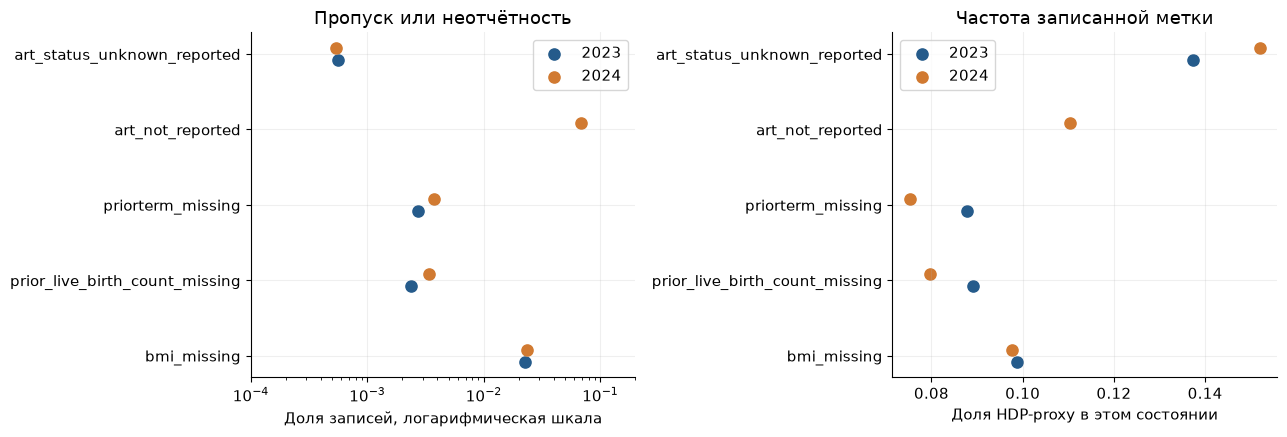

In [6]:
masks=pd.read_csv(OUT/"input_masks_by_year.csv")
display(masks.round(4))
assert set(MISSING_MASKS + QUALITY_MASKS)==set(masks["mask"])
selected=masks.loc[((masks["mask"].isin(MISSING_MASKS)) & masks.value.eq(1)) | (masks["mask"].eq("art_source_reported") & masks.value.eq(0)) | (masks["mask"].eq("art_status_unknown_reported") & masks.value.eq(1))].copy()
selected["state"]=selected["mask"].replace({"art_source_reported":"art_not_reported"})
selected["fraction"]=selected.apply(lambda row: row.rows/int(checks.loc[str(row.year),"eligible_singleton_rows"]),axis=1)
labels=list(selected.state.unique())
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for year,color,shift in [(2023,BLUE,-.08),(2024,ORANGE,.08)]:
    part=selected.loc[selected.year.eq(year)]
    position=np.array([labels.index(name) for name in part.state])+shift
    positive=part.rows.gt(0).to_numpy()
    axes[0].scatter(part.fraction.to_numpy()[positive],position[positive],label=str(year),color=color,s=65)
    axes[1].scatter(part.event_rate.to_numpy()[positive],position[positive],label=str(year),color=color,s=65)
axes[0].set(xscale="log",xlim=(1e-4,.2),xlabel="Доля записей, логарифмическая шкала",title="Пропуск или неотчётность")
axes[1].set(xlabel="Доля HDP-proxy в этом состоянии",title="Частота записанной метки")
for ax in axes: ax.set_yticks(range(len(labels)),labels); ax.legend()
plt.tight_layout();plt.show()

## 5. Импутация расы в источнике NCHS

not_imputed   imputed  fraction_imputed
year mrace6                                         
2023 1         2280736.0  222553.0            0.0889
     2          466987.0   35667.0            0.0710
     3           28681.0    4207.0            0.1279
     4          207702.0   11032.0            0.0504
     5           11122.0    2240.0            0.1676
     6           98787.0       0.0            0.0000
2024 1         2296491.0  234319.0            0.0926
     2          449107.0   35599.0            0.0734
     3           28384.0    4611.0            0.1397
     4          218676.0   11600.0            0.0504
     5           11308.0    2234.0            0.1650
     6          101807.0       0.0            0.0000

Доля импутированной расы в выбранной когорте:


year
2023    0.0818
2024    0.0850
Name: fraction_imputed, dtype: float64

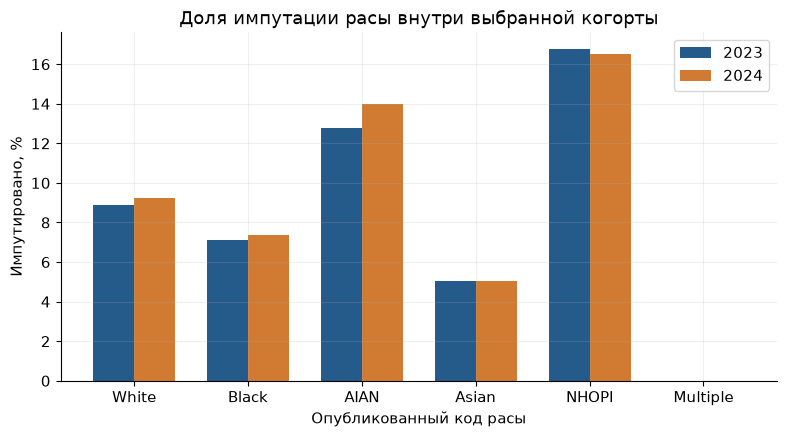

In [7]:
race_imp=audit_race_imputation()
race_counts=race_imp.pivot_table(index=["year","mrace6"],columns="imputed",values="rows",fill_value=0)
race_counts.columns=["not_imputed" if int(code)==0 else "imputed" for code in race_counts.columns]
race_counts["fraction_imputed"]=race_counts.imputed/(race_counts.imputed+race_counts.not_imputed)
display(race_counts.round(4))
by_year=race_imp.groupby(["year","imputed"]).rows.sum().unstack(fill_value=0)
print("Доля импутированной расы в выбранной когорте:")
display((by_year[1]/by_year.sum(axis=1)).rename("fraction_imputed").round(4))
fig,ax=plt.subplots(figsize=(8,4.5))
x=np.arange(6)
for year,color,shift in [(2023,BLUE,-.18),(2024,ORANGE,.18)]:
    part=race_counts.loc[year].reindex(range(1,7))
    ax.bar(x+shift,100*part.fraction_imputed,width=.36,label=str(year),color=color)
ax.set_xticks(x,[RACE6[code] for code in range(1,7)])
ax.set(xlabel="Опубликованный код расы",ylabel="Импутировано, %",title="Доля импутации расы внутри выбранной когорты")
ax.legend();plt.tight_layout();plt.show()

## Интерпретация

`audit.json` содержит SHA-256 архивов, количества до/после исключения и сверку общего `RF_GHYPE` с официальной статистикой NCHS. `input_masks_by_year.csv` различает пропуск индивидуального значения, неотчётность источника ART и неизвестный ответ при отчётности. `race_imputation_by_year.csv` вычисляется отдельно по исходным архивам на **той же когорте**: опубликованный `MRACE6` может быть импутирован даже при отсутствии пропусков в подготовленном файле. Маски BMI/анамнеза входят в основную модель; маска отчётности ART служит только для выбора маршрута ранней модели. Фолды дают распределение метрик на смешанных годах; отдельный тест переноса 2023→2024 находится в ноутбуке 06. См. `MODEL_INPUT_CONTRACT.md`.